# DSCI 552 - Homework 4
### Xinyi Wu

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### 1(a) Download and Load the AReM Dataset

In [2]:
import os
import zipfile
import pandas as pd
import numpy as np

zip_path = "AReM.zip"
extract_path = "AReM"

# Unzip the dataset if it has not already been extracted
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

data_path = os.path.join("AReM", "AReM")

print("Data path:", data_path)
print("Activities:", os.listdir(data_path))

Data path: AReM/AReM
Activities: ['sitting', 'bending1', '.DS_Store', 'bendingType.pdf', 'standing', 'lying', 'bending2', 'walking', 'cycling', 'sensorsPlacement.pdf']


In [3]:
data_path = os.path.join("AReM", "AReM")

activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

total = 0

for activity in activities:
    folder = os.path.join(data_path, activity)

    csv_files = [
        f for f in os.listdir(folder)
        if f.endswith(".csv")
    ]

    print(f"{activity}: {len(csv_files)} datasets")
    total += len(csv_files)

print("\nTotal:", total)

bending1: 7 datasets
bending2: 6 datasets
cycling: 15 datasets
lying: 15 datasets
sitting: 15 datasets
standing: 15 datasets
walking: 15 datasets

Total: 88


### 1(b) Train/Test Split

In [4]:
train_files = []
test_files = []

for activity in activities:
    folder = os.path.join(data_path, activity)

    csv_files = sorted(
        [f for f in os.listdir(folder) if f.endswith(".csv")],
        key=lambda x: int(x.replace("dataset", "").replace(".csv", ""))
    )

    for file in csv_files:
        dataset_num = int(file.replace("dataset", "").replace(".csv", ""))

        if activity in ["bending1", "bending2"]:
            is_test = dataset_num in [1, 2]
        else:
            is_test = dataset_num in [1, 2, 3]

        record = (activity, file)

        if is_test:
            test_files.append(record)
        else:
            train_files.append(record)

print("Training instances:", len(train_files))
print("Test instances:", len(test_files))
print("Total:", len(train_files) + len(test_files))

print("\nTest set:")
for item in test_files:
    print(item)

Training instances: 69
Test instances: 19
Total: 88

Test set:
('bending1', 'dataset1.csv')
('bending1', 'dataset2.csv')
('bending2', 'dataset1.csv')
('bending2', 'dataset2.csv')
('cycling', 'dataset1.csv')
('cycling', 'dataset2.csv')
('cycling', 'dataset3.csv')
('lying', 'dataset1.csv')
('lying', 'dataset2.csv')
('lying', 'dataset3.csv')
('sitting', 'dataset1.csv')
('sitting', 'dataset2.csv')
('sitting', 'dataset3.csv')
('standing', 'dataset1.csv')
('standing', 'dataset2.csv')
('standing', 'dataset3.csv')
('walking', 'dataset1.csv')
('walking', 'dataset2.csv')
('walking', 'dataset3.csv')


### 1(c)(i) Time-Domain Features

Common time-domain features used in time series classification include:

- Minimum
- Maximum
- Mean
- Median
- Standard deviation
- Variance
- First quartile
- Third quartile
- Interquartile range
- Range
- Root mean square (RMS)
- Skewness
- Kurtosis
- Zero-crossing rate

In [5]:
import pandas as pd

sample_path = os.path.join(data_path, "bending1", "dataset1.csv")

with open(sample_path, "r") as f:
    for i in range(10):
        print(repr(f.readline()))

'# Task: bending1\n'
'# Frequency (Hz): 20\n'
'# Clock (millisecond): 250\n'
'# Duration (seconds): 120\n'
'# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23\n'
'0,39.25,0.43,22.75,0.43,33.75,1.30\n'
'250,39.25,0.43,23.00,0.00,33.00,0.00\n'
'500,39.25,0.43,23.25,0.43,33.00,0.00\n'
'750,39.50,0.50,23.00,0.71,33.00,0.00\n'
'1000,39.50,0.50,24.00,0.00,33.00,0.00\n'


In [6]:
columns = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

df = pd.read_csv(
    sample_path,
    skiprows=5,
    header=None,
    names=columns
)

print("Shape:", df.shape)
print()
print(df.head())

Shape: (480, 7)

   time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0     0      39.25       0.43      22.75       0.43      33.75        1.3
1   250      39.25       0.43      23.00       0.00      33.00        0.0
2   500      39.25       0.43      23.25       0.43      33.00        0.0
3   750      39.50       0.50      23.00       0.71      33.00        0.0
4  1000      39.50       0.50      24.00       0.00      33.00        0.0


In [7]:
import numpy as np

time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

def extract_features(df):
    features = {}

    for i, col in enumerate(time_series_columns, start=1):
        series = pd.to_numeric(df[col], errors="coerce").dropna()

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"1st_quart{i}"] = series.quantile(0.25)
        features[f"3rd_quart{i}"] = series.quantile(0.75)

    return features

In [8]:
import io

def read_arem_file(file_path):
    # Read raw text
    with open(file_path, "r") as f:
        lines = f.readlines()

    # Remove trailing commas from data lines if present
    cleaned_lines = []
    for line in lines:
        line = line.rstrip("\n")

        if line.endswith(","):
            line = line[:-1]

        cleaned_lines.append(line)

    cleaned_text = "\n".join(cleaned_lines)

    df = pd.read_csv(
        io.StringIO(cleaned_text),
        skiprows=5,
        header=None,
        names=columns
    )

    return df

### 1(c)(ii) Extract Time-Domain Features

In [9]:
all_features = []

for activity in activities:
    folder = os.path.join(data_path, activity)

    csv_files = sorted(
        [f for f in os.listdir(folder) if f.endswith(".csv")],
        key=lambda x: int(x.replace("dataset", "").replace(".csv", ""))
    )

    for file in csv_files:
        file_path = os.path.join(folder, file)

        # Read and clean the dataset
        temp_df = read_arem_file(file_path)

        # Extract 42 time-domain features
        features = extract_features(temp_df)

        # Keep activity and dataset names
        features["activity"] = activity
        features["dataset"] = file

        all_features.append(features)

feature_df = pd.DataFrame(all_features)

print("Number of instances:", feature_df.shape[0])
print("Number of extracted features:", feature_df.shape[1] - 2)
print("Total columns including activity and dataset:", feature_df.shape[1])

feature_df.head()

Number of instances: 88
Number of extracted features: 42
Total columns including activity and dataset: 44


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,dataset
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30,bending1,dataset1.csv
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30,bending1,dataset2.csv
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94,bending1,dataset3.csv
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00,bending1,dataset4.csv
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50,bending1,dataset5.csv


### 1(c)(iii) Standard Deviations and 90% Bootstrap Confidence Intervals

In [10]:
feature_columns = [
    col for col in feature_df.columns
    if col not in ["activity", "dataset"]
]

feature_std = feature_df[feature_columns].std()

print("Number of features:", len(feature_std))
print()
print(feature_std)

Number of features: 42

min1          9.624011
max1          4.207745
mean1         5.276431
median1       5.386624
std1          1.771282
1st_quart1    6.127846
3rd_quart1    5.031028
min2          0.000000
max2          5.059656
mean2         1.577908
median2       1.413545
std2          0.885875
1st_quart2    0.948434
3rd_quart2    2.131337
min3          2.954516
max3          4.819848
mean3         3.976754
median3       4.009687
std3          0.952011
1st_quart3    4.184148
3rd_quart3    4.153451
min4          0.000000
max4          2.181809
mean4         1.168268
median4       1.148591
std4          0.458612
1st_quart4    0.844919
3rd_quart4    1.555235
min5          6.121205
max5          5.773355
mean5         5.704025
median5       5.844368
std5          1.012358
1st_quart5    6.122142
3rd_quart5    5.563553
min6          0.046101
max6          2.533515
mean6         1.157222
median6       1.089858
std6          0.516968
1st_quart6    0.761542
3rd_quart6    1.526871
dtype: flo

In [11]:
np.random.seed(42)

bootstrap_results = []

for feature in feature_columns:
    values = feature_df[feature].dropna().values

    bootstrap_stds = []

    for _ in range(1000):
        sample = np.random.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_stds.append(
            np.std(sample, ddof=1)
        )

    lower = np.percentile(bootstrap_stds, 5)
    upper = np.percentile(bootstrap_stds, 95)

    bootstrap_results.append({
        "Feature": feature,
        "Standard Deviation": np.std(values, ddof=1),
        "90% CI Lower": lower,
        "90% CI Upper": upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

bootstrap_df

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.624011,8.321447,10.822204
1,max1,4.207745,3.054311,5.118384
2,mean1,5.276431,4.600504,5.861422
3,median1,5.386624,4.709493,5.982450
4,std1,1.771282,1.579549,1.944076
5,1st_quart1,6.127846,5.520521,6.626887
6,3rd_quart1,5.031028,4.198566,5.760116
7,min2,0.000000,0.000000,0.000000
8,max2,5.059656,4.615051,5.409296
9,mean2,1.577908,1.418010,1.711959


### 1(c)(iv) Selection of Important Time-Domain Features

The three most important time-domain features I selected are **minimum, mean, and maximum**.

The mean represents the overall level of a time series, while the minimum and maximum capture its lower and upper extremes. Together, these features provide a simple representation of the central tendency and range of the sensor measurements.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a) Binary Classification Using Logistic Regression

#### 2(a)(i) Scatter Plots

In [12]:
# HW4 - Question 2(a)(i)

# Use training instances only
train_plot_df = feature_df[
    ~feature_df.apply(
        lambda row: (
            row["dataset"] in ["dataset1.csv", "dataset2.csv"]
            if row["activity"] in ["bending1", "bending2"]
            else row["dataset"] in [
                "dataset1.csv", "dataset2.csv", "dataset3.csv"
            ]
        ),
        axis=1
    )
].copy()

# Binary class labels
train_plot_df["class"] = train_plot_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)

print("Training instances:", len(train_plot_df))
print(train_plot_df["class"].value_counts())

Training instances: 69
class
other      60
bending     9
Name: count, dtype: int64


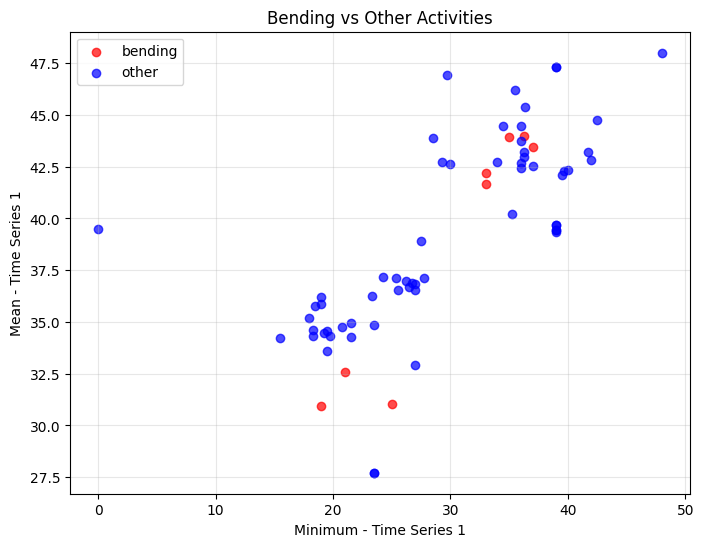

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for label, color in [("bending", "red"), ("other", "blue")]:
    subset = train_plot_df[train_plot_df["class"] == label]

    plt.scatter(
        subset["min1"],
        subset["mean1"],
        color=color,
        label=label,
        alpha=0.7
    )

plt.xlabel("Minimum - Time Series 1")
plt.ylabel("Mean - Time Series 1")
plt.title("Bending vs Other Activities")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

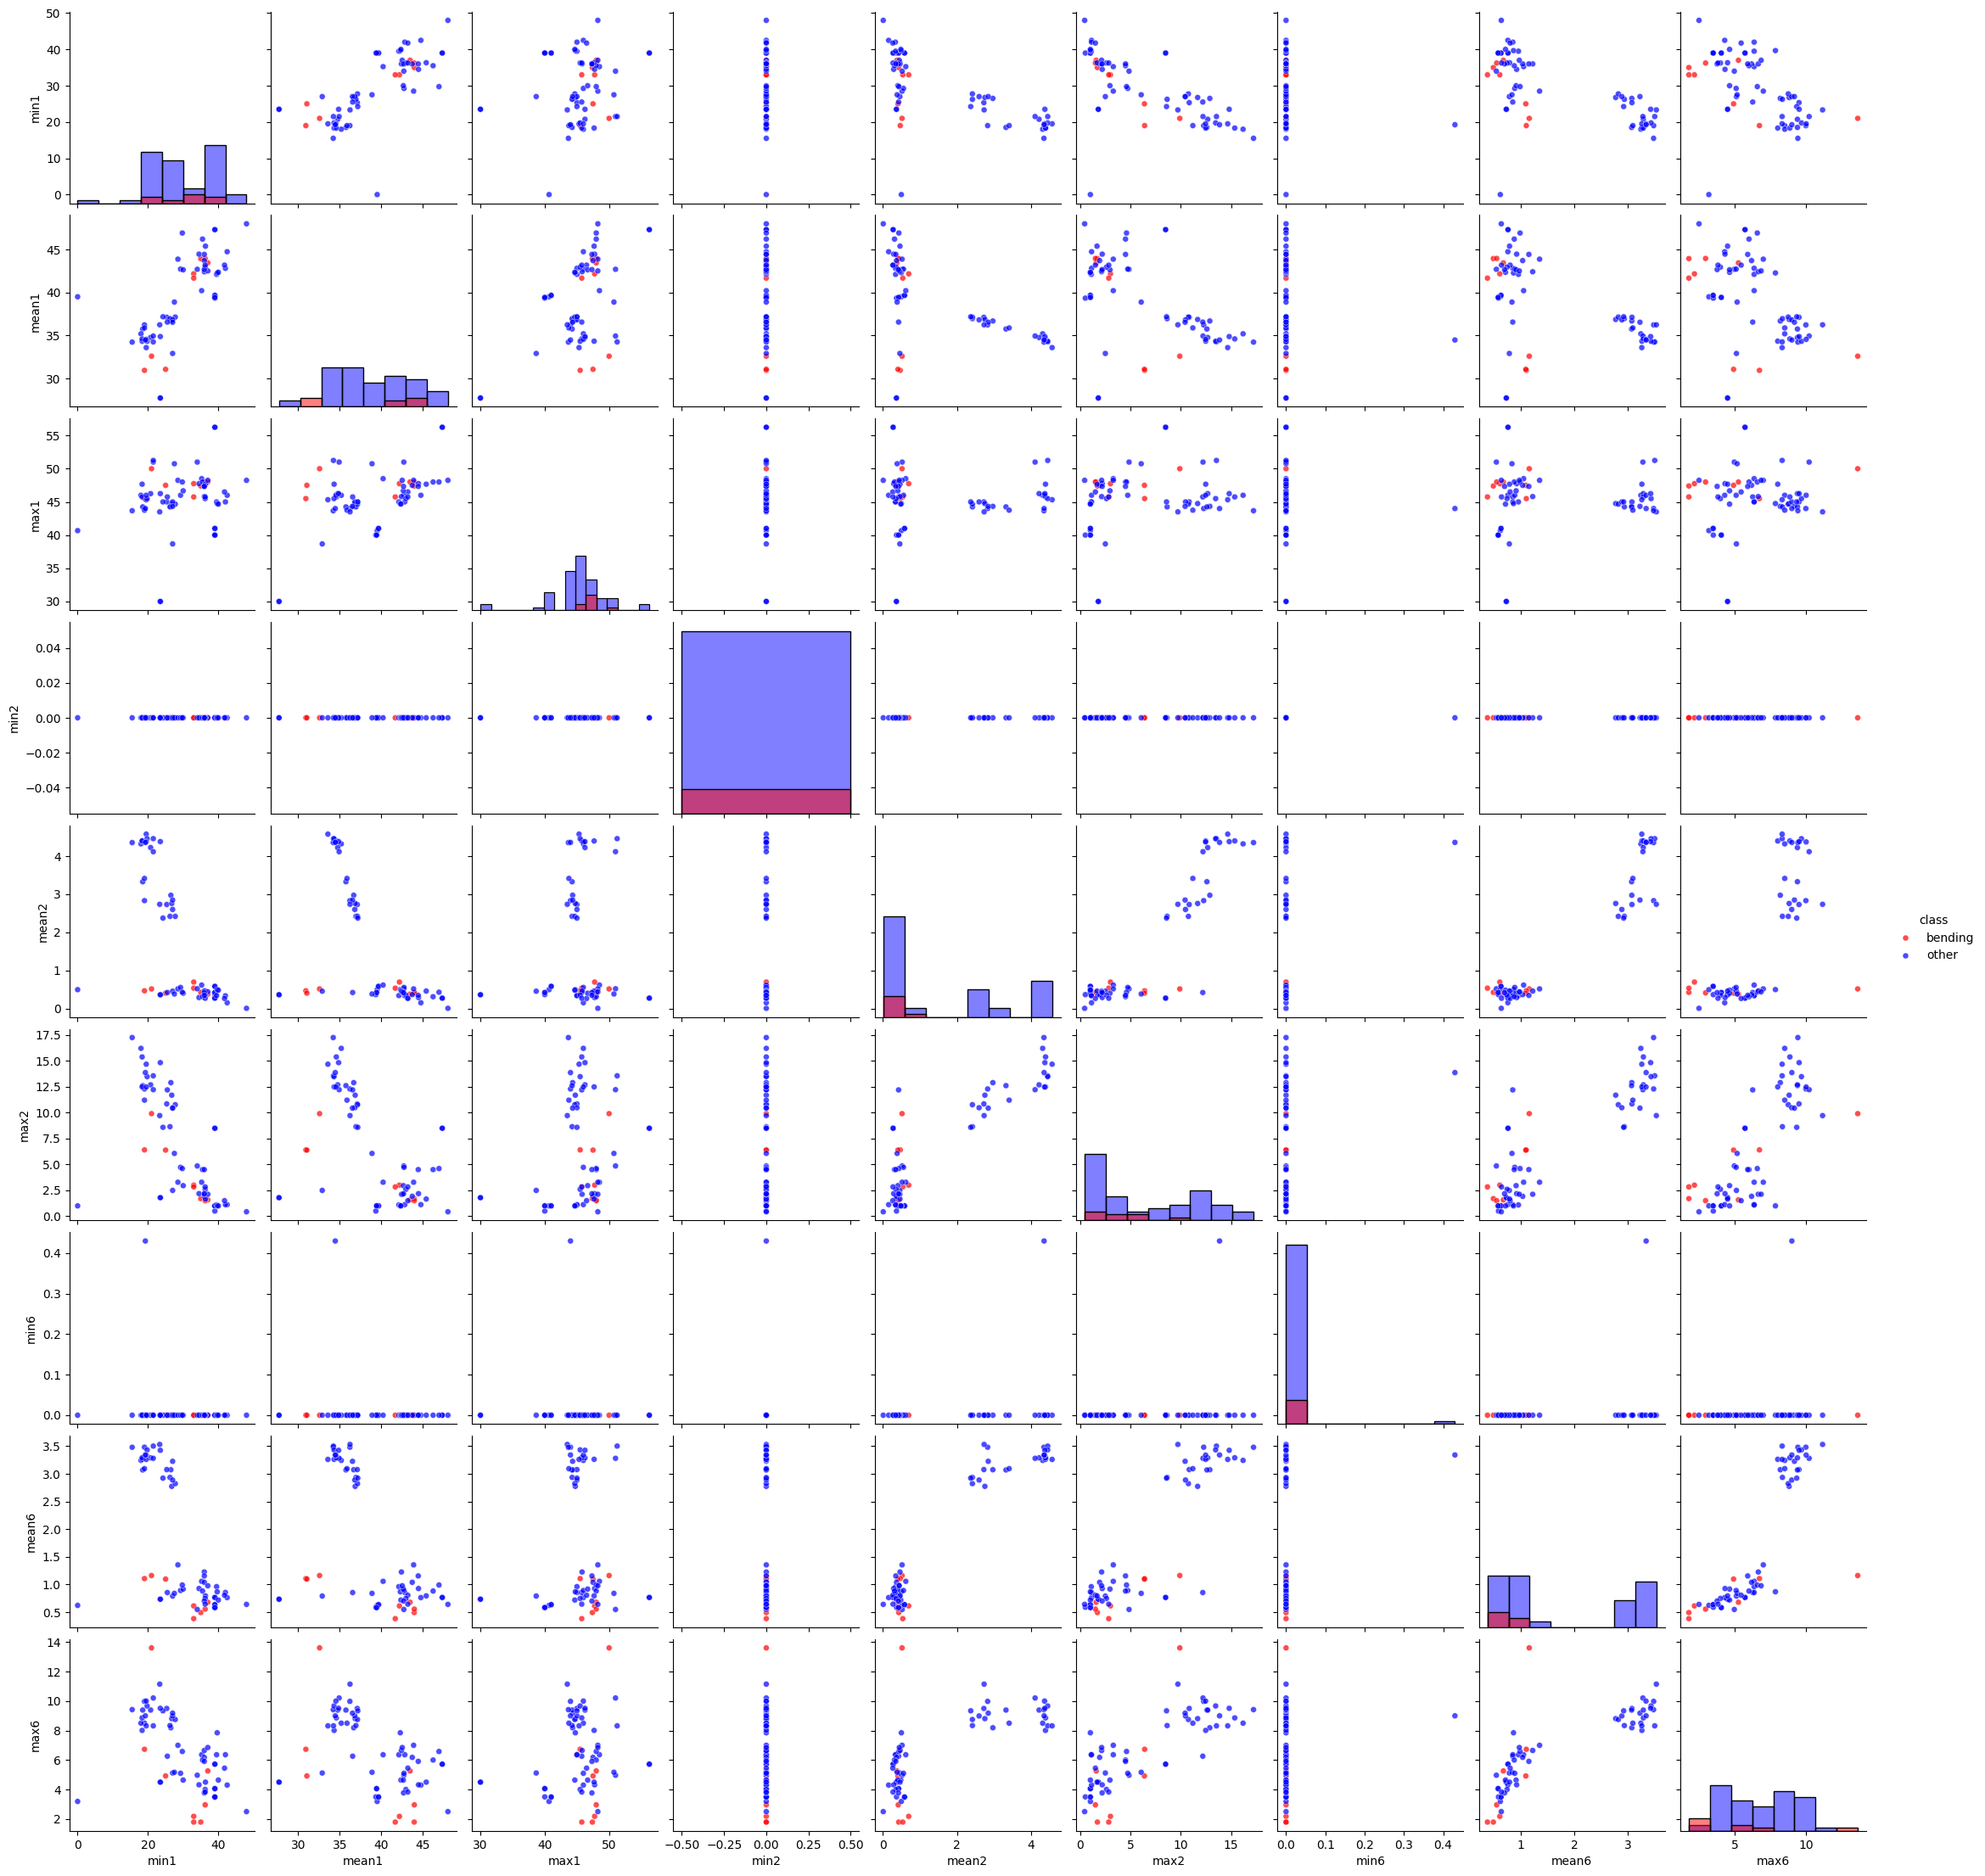

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

selected_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

sns.pairplot(
    train_plot_df,
    vars=selected_features,
    hue="class",
    palette={"bending": "red", "other": "blue"},
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 25}
)

plt.show()

**Observations:**

The scatter plots show that bending and other activities overlap in several feature combinations, although some features show differences between the two classes. The minimum values of time series 2 and 6 are often close to zero, which limits their usefulness for distinguishing the classes.

Overall, the selected features provide some information for classification, but they do not perfectly separate bending from other activities. Combining multiple features may improve classification performance.

### 2(a)(ii) Time Series Splitting

In [15]:
# Split one time series instance into 2 parts

sample_path = os.path.join(
    data_path, "bending1", "dataset1.csv"
)

sample_df = read_arem_file(sample_path)

# Split into two approximately equal parts
indices = np.array_split(np.arange(len(sample_df)), 2)
parts = [sample_df.iloc[idx] for idx in indices]

print("Original shape:", sample_df.shape)
print("Part 1 shape:", parts[0].shape)
print("Part 2 shape:", parts[1].shape)

Original shape: (480, 7)
Part 1 shape: (240, 7)
Part 2 shape: (240, 7)


In [16]:
# Extract features from each half

features_part1 = extract_features(parts[0])
features_part2 = extract_features(parts[1])

print("Part 1 features:", len(features_part1))
print("Part 2 features:", len(features_part2))
print("Total features:", len(features_part1) + len(features_part2))

Part 1 features: 42
Part 2 features: 42
Total features: 84


In [17]:
# Extract features from 2 time segments for all instances

split_feature_rows = []

for activity in activities:
    folder = os.path.join(data_path, activity)

    csv_files = sorted(
        [f for f in os.listdir(folder) if f.endswith(".csv")],
        key=lambda x: int(x.replace("dataset", "").replace(".csv", ""))
    )

    for file in csv_files:
        file_path = os.path.join(folder, file)
        df = read_arem_file(file_path)

        indices = np.array_split(np.arange(len(df)), 2)
        parts = [df.iloc[idx] for idx in indices]

        row = {
            "activity": activity,
            "dataset": file
        }

        for part_number, part in enumerate(parts, start=1):
            features = extract_features(part)

            for feature_name, value in features.items():
                row[f"{feature_name}_part{part_number}"] = value

        split_feature_rows.append(row)

split_feature_df = pd.DataFrame(split_feature_rows)

print("Instances:", len(split_feature_df))
print("Features per instance:", split_feature_df.shape[1] - 2)

split_feature_df.head()

Instances: 88
Features per instance: 84


,activity,dataset,min1_part1,max1_part1,mean1_part1,median1_part1,std1_part1,1st_quart1_part1,3rd_quart1_part1,min2_part1,...,std5_part2,1st_quart5_part2,3rd_quart5_part2,min6_part2,max6_part2,mean6_part2,median6_part2,std6_part2,1st_quart6_part2,3rd_quart6_part2
0,bending1,dataset1.csv,38.00,42.33,40.946958,41.25,1.102963,40.3100,42.00,0.0,...,2.838110,31.31,36.5000,0.0,1.92,0.552167,0.43,0.510494,0.0,0.94
1,bending1,dataset2.csv,41.75,44.25,42.643292,42.50,0.641849,42.0000,43.33,0.0,...,2.283931,30.00,33.7500,0.0,3.11,0.533583,0.43,0.575061,0.0,0.87
2,bending1,dataset3.csv,36.50,46.50,44.057167,44.50,1.556971,43.2500,45.00,0.0,...,2.298693,33.00,36.2500,0.0,1.50,0.388333,0.00,0.478528,0.0,0.71
3,bending1,dataset4.csv,33.75,47.75,43.278875,45.00,3.473355,42.0000,45.25,0.0,...,3.760118,28.75,33.7500,0.0,2.18,0.586083,0.47,0.491873,0.0,0.87
4,bending1,dataset5.csv,33.00,45.75,41.621208,42.33,3.118644,39.6525,44.25,0.0,...,2.062647,28.31,30.5625,0.0,1.50,0.347500,0.43,0.363144,0.0,0.50


In [18]:
# HW4 - Train/Test Split

def is_test_instance(row):
    dataset_num = int(
        row["dataset"].replace("dataset", "").replace(".csv", "")
    )

    if row["activity"] in ["bending1", "bending2"]:
        return dataset_num in [1, 2]
    else:
        return dataset_num in [1, 2, 3]

test_mask = split_feature_df.apply(is_test_instance, axis=1)

train_split_df = split_feature_df[~test_mask].copy()
test_split_df = split_feature_df[test_mask].copy()

print("Training instances:", len(train_split_df))
print("Test instances:", len(test_split_df))
print("Features:", train_split_df.shape[1] - 2)

Training instances: 69
Test instances: 19
Features: 84


In [19]:
# Prepare data for binary classification

feature_cols = [
    col for col in train_split_df.columns
    if col not in ["activity", "dataset"]
]

X_train = train_split_df[feature_cols]
X_test = test_split_df[feature_cols]

y_train = train_split_df["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

y_test = test_split_df["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

X_train: (69, 84)
X_test: (19, 84)

Training labels:
activity
0    60
1     9
Name: count, dtype: int64


In [20]:
# Check missing values in training and test features

print("Training missing values:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nTest missing values:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

print("\nTraining rows with NaN:", X_train.isna().any(axis=1).sum())
print("Test rows with NaN:", X_test.isna().any(axis=1).sum())

Training missing values:
min1_part1          1
max1_part1          1
mean1_part1         1
median1_part1       1
std1_part1          1
                   ..
mean6_part2         1
median6_part2       1
std6_part2          1
1st_quart6_part2    1
3rd_quart6_part2    1
Length: 84, dtype: int64

Test missing values:
Series([], dtype: int64)

Training rows with NaN: 1
Test rows with NaN: 0


In [21]:
# Find the training instance with missing features

bad_rows = X_train.isna().any(axis=1)

print(
    train_split_df.loc[
        bad_rows,
        ["activity", "dataset"]
    ]
)

    activity       dataset
10  bending2  dataset4.csv


In [22]:
bad_file = os.path.join(
    data_path, "bending2", "dataset4.csv"
)

# Check the original file
with open(bad_file, "r") as f:
    lines = f.readlines()

print("Total lines:", len(lines))
print("\nFirst 10 lines:")

for line in lines[:10]:
    print(repr(line))

# Check the cleaned dataframe
bad_df = read_arem_file(bad_file)

print("\nDataFrame shape:", bad_df.shape)
print(bad_df.head())

Total lines: 485

First 10 lines:
'# Task: bending2\n'
'# Frequency (Hz): 20\n'
'# Clock (millisecond): 250\n'
'# Duration (seconds): 120\n'
'# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23\n'
'0 32.50 0.50 0.00 0.00 19.00 1.00 \n'
'250 32.50 0.50 0.00 0.00 18.50 0.50 \n'
'500 32.75 0.43 1.00 0.00 18.00 0.00 \n'
'750 32.50 0.50 0.00 0.00 17.50 0.50 \n'
'1000 32.50 0.50 7.50 0.50 17.50 0.87 \n'

DataFrame shape: (480, 7)
                                    time  avg_rss12  var_rss12  avg_rss13  \
0     0 32.50 0.50 0.00 0.00 19.00 1.00         NaN        NaN        NaN   
1   250 32.50 0.50 0.00 0.00 18.50 0.50         NaN        NaN        NaN   
2   500 32.75 0.43 1.00 0.00 18.00 0.00         NaN        NaN        NaN   
3   750 32.50 0.50 0.00 0.00 17.50 0.50         NaN        NaN        NaN   
4  1000 32.50 0.50 7.50 0.50 17.50 0.87         NaN        NaN        NaN   

   var_rss13  avg_rss23  var_rss23  
0        NaN        NaN        NaN  
1        Na

In [23]:
import io

def read_arem_file(file_path):
    with open(file_path, "r") as f:
        lines = f.readlines()

    cleaned_lines = []

    for line in lines:
        line = line.strip()

        if line.endswith(","):
            line = line[:-1]

        cleaned_lines.append(line)

    cleaned_text = "\n".join(cleaned_lines)

    df = pd.read_csv(
        io.StringIO(cleaned_text),
        sep=r"[,\s]+",
        engine="python",
        skiprows=5,
        header=None,
        names=columns
    )

    return df

In [24]:
bad_df = read_arem_file(bad_file)

print("Shape:", bad_df.shape)
print("Missing values:", bad_df.isna().sum().sum())
print(bad_df.head())

Shape: (480, 7)
Missing values: 0
   time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0     0      32.50       0.50        0.0        0.0       19.0       1.00
1   250      32.50       0.50        0.0        0.0       18.5       0.50
2   500      32.75       0.43        1.0        0.0       18.0       0.00
3   750      32.50       0.50        0.0        0.0       17.5       0.50
4  1000      32.50       0.50        7.5        0.5       17.5       0.87


In [25]:
# Rebuild the feature table using the fixed reader

split_feature_rows = []

for activity in activities:
    folder = os.path.join(data_path, activity)

    for file in sorted(
        [f for f in os.listdir(folder) if f.endswith(".csv")],
        key=lambda x: int(x.replace("dataset", "").replace(".csv", ""))
    ):
        df = read_arem_file(os.path.join(folder, file))

        indices = np.array_split(np.arange(len(df)), 2)
        parts = [df.iloc[idx] for idx in indices]

        row = {"activity": activity, "dataset": file}

        for i, part in enumerate(parts, start=1):
            features = extract_features(part)

            for name, value in features.items():
                row[f"{name}_part{i}"] = value

        split_feature_rows.append(row)

split_feature_df = pd.DataFrame(split_feature_rows)

print("Instances:", len(split_feature_df))
print("Features:", split_feature_df.shape[1] - 2)
print("Missing values:", split_feature_df.isna().sum().sum())

Instances: 88
Features: 84
Missing values: 0


In [26]:
# Rebuild train/test sets using the cleaned features

test_mask = split_feature_df.apply(is_test_instance, axis=1)

train_split_df = split_feature_df[~test_mask].copy()
test_split_df = split_feature_df[test_mask].copy()

feature_cols = [
    col for col in split_feature_df.columns
    if col not in ["activity", "dataset"]
]

X_train = train_split_df[feature_cols]
X_test = test_split_df[feature_cols]

y_train = train_split_df["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

y_test = test_split_df["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Missing values:", X_train.isna().sum().sum())

X_train: (69, 84)
X_test: (19, 84)
Missing values: 0


In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        random_state=42
    )
)

# Train the model
model.fit(X_train, y_train)

# Predict training data
y_train_pred = model.predict(X_train)

print("Training Accuracy:", model.score(X_train, y_train))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred))

Training Accuracy: 1.0

Confusion Matrix:
[[60  0]
 [ 0  9]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



In [28]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("CV Accuracy Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("CV Error Rate:", 1 - cv_scores.mean())

CV Accuracy Scores: [1.         0.85714286 0.85714286 0.92857143 1.        ]
Mean CV Accuracy: 0.9285714285714286
CV Error Rate: 0.0714285714285714


In [29]:
def extract_split_features(df, l):
    indices = np.array_split(np.arange(len(df)), l)
    parts = [df.iloc[idx] for idx in indices]

    row = {}

    for i, part in enumerate(parts, start=1):
        features = extract_features(part)

        for name, value in features.items():
            row[f"{name}_part{i}"] = value

    return row


# Test different numbers of splits
for l in [1, 2, 3, 4]:
    sample_features = extract_split_features(sample_df, l)

    print(f"l = {l}: {len(sample_features)} features")

l = 1: 42 features
l = 2: 84 features
l = 3: 126 features
l = 4: 168 features


In [30]:
# Build feature tables for different l values

def build_feature_table(l):
    rows = []

    for activity in activities:
        folder = os.path.join(data_path, activity)

        files = sorted(
            [f for f in os.listdir(folder) if f.endswith(".csv")],
            key=lambda x: int(x.replace("dataset", "").replace(".csv", ""))
        )

        for file in files:
            df = read_arem_file(os.path.join(folder, file))

            row = {
                "activity": activity,
                "dataset": file
            }

            row.update(extract_split_features(df, l))
            rows.append(row)

    return pd.DataFrame(rows)


for l in [1, 2, 3, 4]:
    table = build_feature_table(l)

    print(
        f"l={l}: {len(table)} instances, "
        f"{table.shape[1] - 2} features, "
        f"{table.isna().sum().sum()} missing values"
    )

l=1: 88 instances, 42 features, 0 missing values
l=2: 88 instances, 84 features, 0 missing values
l=3: 88 instances, 126 features, 0 missing values
l=4: 88 instances, 168 features, 0 missing values


In [31]:
# Compare different time-series split values using 5-fold CV

cv_results = []

for l in [1, 2, 3, 4]:
    table = build_feature_table(l)

    test_mask = table.apply(is_test_instance, axis=1)
    train_table = table[~test_mask]

    X = train_table.drop(columns=["activity", "dataset"])
    y = train_table["activity"].isin(
        ["bending1", "bending2"]
    ).astype(int)

    cv_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=10000,
            class_weight="balanced",
            random_state=42
        )
    )

    scores = cross_val_score(
        cv_model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "l": l,
        "features": X.shape[1],
        "CV Accuracy": scores.mean(),
        "CV Error": 1 - scores.mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

,l,features,CV Accuracy,CV Error
0,1,42,0.957143,0.042857
1,2,84,0.928571,0.071429
2,3,126,0.928571,0.071429
3,4,168,0.942857,0.057143


In [32]:
from sklearn.feature_selection import RFE

# Use l=1 as a starting example
table_l1 = build_feature_table(1)

mask_l1 = table_l1.apply(is_test_instance, axis=1)
train_l1 = table_l1[~mask_l1]

X_l1 = train_l1.drop(columns=["activity", "dataset"])

y_l1 = train_l1["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

# Standardize features
scaler = StandardScaler()
X_l1_scaled = scaler.fit_transform(X_l1)

# Select 10 features as an initial example
rfe = RFE(
    estimator=LogisticRegression(
        max_iter=10000,
        class_weight="balanced"
    ),
    n_features_to_select=10
)

rfe.fit(X_l1_scaled, y_l1)

selected_features = X_l1.columns[rfe.support_]

print("Selected features:")
print(selected_features.tolist())
print("\nNumber selected:", len(selected_features))

Selected features:
['mean1_part1', '3rd_quart1_part1', '3rd_quart2_part1', 'min5_part1', 'max5_part1', 'mean5_part1', '1st_quart5_part1', '3rd_quart5_part1', 'median6_part1', '1st_quart6_part1']

Number selected: 10


In [33]:
from sklearn.pipeline import Pipeline

rfe_cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=10000,
            class_weight="balanced"
        ),
        n_features_to_select=10
    )),
    ("classifier", LogisticRegression(
        max_iter=10000,
        class_weight="balanced",
        random_state=42
    ))
])

rfe_cv_scores = cross_val_score(
    rfe_cv_model,
    X_l1,
    y_l1,
    cv=cv,
    scoring="accuracy"
)

print("RFE CV Scores:", rfe_cv_scores)
print("Mean CV Accuracy:", rfe_cv_scores.mean())
print("CV Error:", 1 - rfe_cv_scores.mean())

RFE CV Scores: [1.         1.         0.85714286 0.92857143 1.        ]
Mean CV Accuracy: 0.9571428571428571
CV Error: 0.04285714285714293


In [34]:
# Compare different numbers of selected features

feature_results = []

for n in [5, 10, 15, 20, 30, 42]:

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=LogisticRegression(
                max_iter=10000,
                class_weight="balanced"
            ),
            n_features_to_select=n
        )),
        ("classifier", LogisticRegression(
            max_iter=10000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_l1,
        y_l1,
        cv=cv,
        scoring="accuracy"
    )

    feature_results.append({
        "Number of Features": n,
        "CV Accuracy": scores.mean(),
        "CV Error": 1 - scores.mean()
    })

feature_results_df = pd.DataFrame(feature_results)

display(feature_results_df)

,Number of Features,CV Accuracy,CV Error
0,5,0.957143,0.042857
1,10,0.957143,0.042857
2,15,0.957143,0.042857
3,20,0.957143,0.042857
4,30,0.957143,0.042857
5,42,0.957143,0.042857


In [35]:
best_rfe = RFE(
    estimator=LogisticRegression(
        max_iter=10000,
        class_weight="balanced"
    ),
    n_features_to_select=5
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_l1)

best_rfe.fit(X_scaled, y_l1)

best_features = X_l1.columns[best_rfe.support_]

print("Selected 5 features:")
print(best_features.tolist())

Selected 5 features:
['3rd_quart1_part1', 'min5_part1', 'max5_part1', 'mean5_part1', '1st_quart6_part1']


In [36]:
table_l2 = build_feature_table(2)

print("Instances:", len(table_l2))
print("Features:", table_l2.shape[1] - 2)
print("Missing values:", table_l2.isna().sum().sum())

Instances: 88
Features: 84
Missing values: 0


In [37]:
mask_l2 = table_l2.apply(is_test_instance, axis=1)

train_l2 = table_l2[~mask_l2]
test_l2 = table_l2[mask_l2]

print("Training instances:", len(train_l2))
print("Test instances:", len(test_l2))

Training instances: 69
Test instances: 19


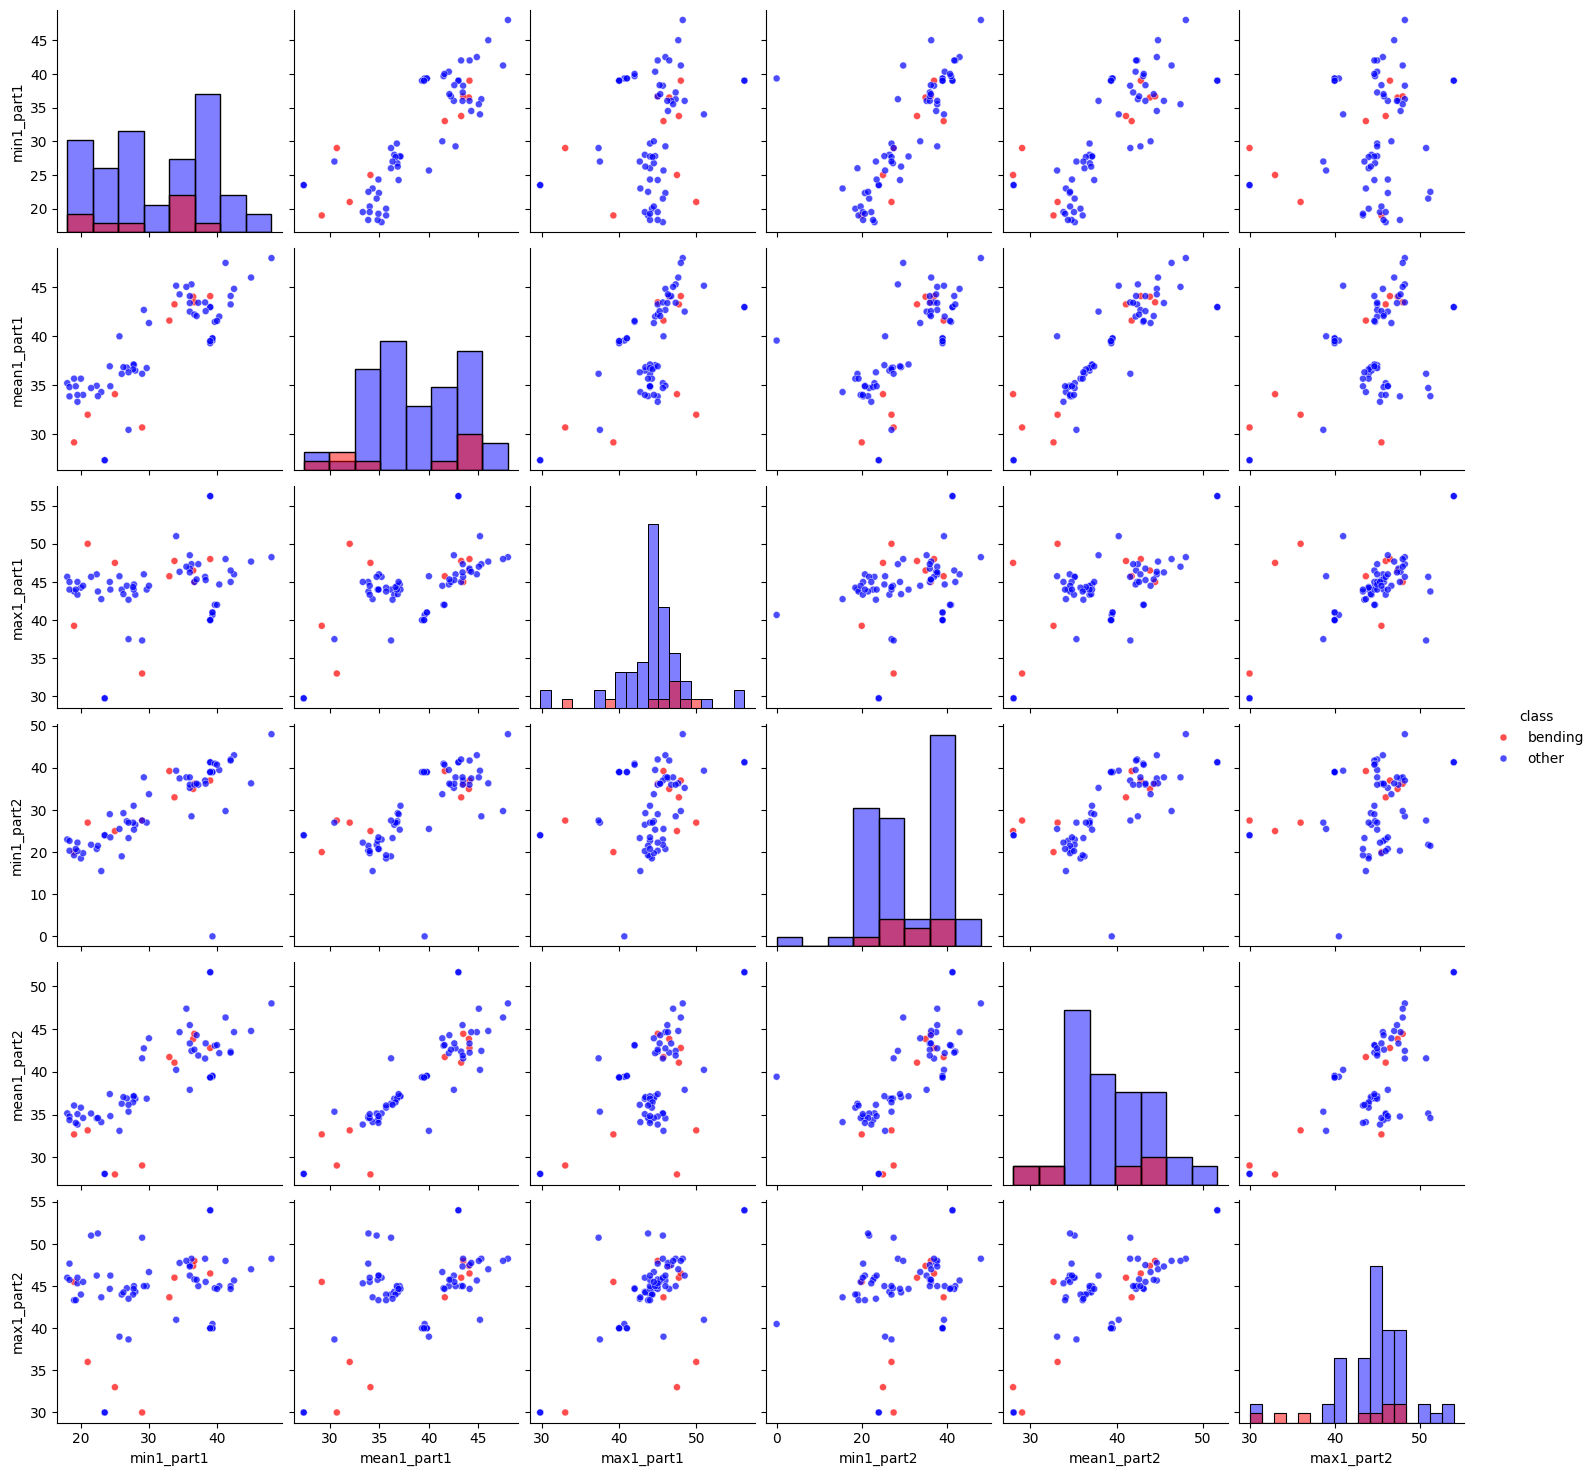

In [38]:
# Scatter plots after splitting each time series into 2 parts

plot_df = build_feature_table(2)
plot_df = plot_df[
    ~plot_df.apply(is_test_instance, axis=1)
].copy()

plot_df["class"] = plot_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)

sns.pairplot(
    plot_df,
    vars=[
        "min1_part1", "mean1_part1", "max1_part1",
        "min1_part2", "mean1_part2", "max1_part2"
    ],
    hue="class",
    palette={"bending": "red", "other": "blue"},
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 25}
)

plt.show()

**Observation:** After dividing each time series into two equal parts, the minimum, mean, and maximum features from both segments were visualized using a scatter plot matrix. Some separation between bending and non-bending activities is visible, although the two classes still overlap. Splitting the time series preserves temporal information that may be useful for classification.

2(a)(iii) Logistic Regression and Cross-Validation

**Class Imbalance:** The training dataset contains 9 bending instances and 60 non-bending instances, indicating a substantial class imbalance. To address this issue, `class_weight="balanced"` was used in logistic regression to give greater importance to the minority class. Stratified 5-fold cross-validation was also applied to preserve approximately the same class proportions across folds.

In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_l2 = train_l2.drop(columns=["activity", "dataset"])

y_l2 = train_l2["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

model_l2 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=10000,
        class_weight="balanced"
    )
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_l2 = cross_val_score(
    model_l2, X_l2, y_l2,
    cv=cv,
    scoring="accuracy"
)

print("Mean CV Accuracy:", scores_l2.mean())
print("CV Error:", 1 - scores_l2.mean())

Mean CV Accuracy: 0.9285714285714286
CV Error: 0.0714285714285714


In [40]:
table_l3 = build_feature_table(3)

mask_l3 = table_l3.apply(is_test_instance, axis=1)
train_l3 = table_l3[~mask_l3]

X_l3 = train_l3.drop(columns=["activity", "dataset"])

y_l3 = train_l3["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

scores_l3 = cross_val_score(
    model_l2,
    X_l3,
    y_l3,
    cv=cv,
    scoring="accuracy"
)

print("Features:", X_l3.shape[1])
print("Mean CV Accuracy:", scores_l3.mean())
print("CV Error:", 1 - scores_l3.mean())

Features: 126
Mean CV Accuracy: 0.9285714285714285
CV Error: 0.07142857142857151


In [41]:
table_l4 = build_feature_table(4)

mask_l4 = table_l4.apply(is_test_instance, axis=1)
train_l4 = table_l4[~mask_l4]

X_l4 = train_l4.drop(columns=["activity", "dataset"])

y_l4 = train_l4["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

scores_l4 = cross_val_score(
    model_l2,
    X_l4,
    y_l4,
    cv=cv,
    scoring="accuracy"
)

print("Features:", X_l4.shape[1])
print("Mean CV Accuracy:", scores_l4.mean())
print("CV Error:", 1 - scores_l4.mean())

Features: 168
Mean CV Accuracy: 0.9428571428571428
CV Error: 0.05714285714285716


In [42]:
# Prepare training data for l = 1 to 20

training_data_by_l = {}

for l in range(1, 21):
    table = build_feature_table(l)

    mask = table.apply(is_test_instance, axis=1)
    train = table[~mask]

    X = train.drop(columns=["activity", "dataset"])
    y = train["activity"].isin(
        ["bending1", "bending2"]
    ).astype(int)

    training_data_by_l[l] = (X, y)

    print(f"l={l}: {X.shape[0]} instances, {X.shape[1]} features")

l=1: 69 instances, 42 features
l=2: 69 instances, 84 features
l=3: 69 instances, 126 features
l=4: 69 instances, 168 features
l=5: 69 instances, 210 features
l=6: 69 instances, 252 features
l=7: 69 instances, 294 features
l=8: 69 instances, 336 features
l=9: 69 instances, 378 features
l=10: 69 instances, 420 features
l=11: 69 instances, 462 features
l=12: 69 instances, 504 features
l=13: 69 instances, 546 features
l=14: 69 instances, 588 features
l=15: 69 instances, 630 features
l=16: 69 instances, 672 features
l=17: 69 instances, 714 features
l=18: 69 instances, 756 features
l=19: 69 instances, 798 features
l=20: 69 instances, 840 features


In [43]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE

X, y = training_data_by_l[1]

rfe_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            max_iter=10000,
            class_weight="balanced"
        ),
        n_features_to_select=5,
        step=0.2
    )),
    ("classifier", LogisticRegression(
        max_iter=10000,
        class_weight="balanced"
    ))
])

scores = cross_val_score(
    rfe_model, X, y,
    cv=cv,
    scoring="accuracy"
)

print("l:", 1)
print("Selected features (p):", 5)
print("CV Accuracy:", scores.mean())
print("CV Error:", 1 - scores.mean())

l: 1
Selected features (p): 5
CV Accuracy: 0.9714285714285715
CV Error: 0.02857142857142847


In [44]:
from sklearn.base import clone

X, y = training_data_by_l[1]

p_results = []

for p in [5, 10, 15, 20, 30, 42]:
    model = clone(rfe_model)
    model.set_params(rfe__n_features_to_select=p)

    scores = cross_val_score(
        model, X, y,
        cv=cv,
        scoring="accuracy"
    )

    p_results.append({
        "p": p,
        "CV Accuracy": scores.mean(),
        "CV Error": 1 - scores.mean()
    })

display(pd.DataFrame(p_results))

,p,CV Accuracy,CV Error
0,5,0.971429,0.028571
1,10,0.957143,0.042857
2,15,0.957143,0.042857
3,20,0.957143,0.042857
4,30,0.957143,0.042857
5,42,0.957143,0.042857


In [45]:
X, y = training_data_by_l[2]

p_results_l2 = []

for p in [5, 10, 15, 20, 30, 42]:
    model = clone(rfe_model)
    model.set_params(rfe__n_features_to_select=p)

    scores = cross_val_score(
        model, X, y,
        cv=cv,
        scoring="accuracy"
    )

    p_results_l2.append({
        "l": 2,
        "p": p,
        "CV Accuracy": scores.mean(),
        "CV Error": 1 - scores.mean()
    })

display(pd.DataFrame(p_results_l2))

,l,p,CV Accuracy,CV Error
0,2,5,0.928571,0.071429
1,2,10,0.942857,0.057143
2,2,15,0.942857,0.057143
3,2,20,0.914286,0.085714
4,2,30,0.900000,0.100000
5,2,42,0.914286,0.085714


In [46]:
joint_results = []

for l in range(3, 21):
    X, y = training_data_by_l[l]

    for p in [5, 10, 15, 20, 30, 42]:
        model = clone(rfe_model)
        model.set_params(rfe__n_features_to_select=p)

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="accuracy"
        )

        joint_results.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores.mean(),
            "CV Error": 1 - scores.mean()
        })

    print(f"Finished l={l}")

display(pd.DataFrame(joint_results).sort_values("CV Error").head(10))

Finished l=3
Finished l=4
Finished l=5
Finished l=6
Finished l=7
Finished l=8
Finished l=9
Finished l=10
Finished l=11
Finished l=12
Finished l=13
Finished l=14
Finished l=15
Finished l=16
Finished l=17
Finished l=18
Finished l=19
Finished l=20


,l,p,CV Accuracy,CV Error
13,5,10,0.971429,0.028571
14,5,15,0.971429,0.028571
45,10,20,0.971429,0.028571
65,13,42,0.971429,0.028571
91,18,10,0.971429,0.028571
103,20,10,0.971429,0.028571
47,10,42,0.957143,0.042857
22,6,30,0.957143,0.042857
90,18,5,0.957143,0.042857
46,10,30,0.957143,0.042857


2(a)(iv) Final Model and Training Evaluation

In [47]:
X_best, y_best = training_data_by_l[1]

final_model = clone(rfe_model)

final_model.set_params(
    rfe__n_features_to_select=5
)

final_model.fit(X_best, y_best)

selected_features = X_best.columns[
    final_model.named_steps["rfe"].support_
]

print("Best l:", 1)
print("Best p:", 5)
print("Selected features:")
print(selected_features.tolist())

Best l: 1
Best p: 5
Selected features:
['3rd_quart1_part1', '1st_quart4_part1', 'min5_part1', 'max5_part1', '1st_quart6_part1']


2(a)(v) Test Set Evaluation

In [48]:
mask_l1 = table_l1.apply(is_test_instance, axis=1)

test_l1 = table_l1[mask_l1]

print("Test instances:", len(test_l1))

Test instances: 19


In [49]:
from sklearn.metrics import accuracy_score, confusion_matrix

X_test_best = test_l1.drop(
    columns=["activity", "dataset"]
)

y_test_best = test_l1["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

y_pred = final_model.predict(X_test_best)

print("Test Accuracy:", accuracy_score(y_test_best, y_pred))
print("Test Error:", 1 - accuracy_score(y_test_best, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test_best, y_pred))

Test Accuracy: 1.0
Test Error: 0.0
Confusion Matrix:
[[15  0]
 [ 0  4]]


In [50]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_best,
    y_pred,
    target_names=["Non-Bending", "Bending"]
))

              precision    recall  f1-score   support

 Non-Bending       1.00      1.00      1.00        15
     Bending       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19



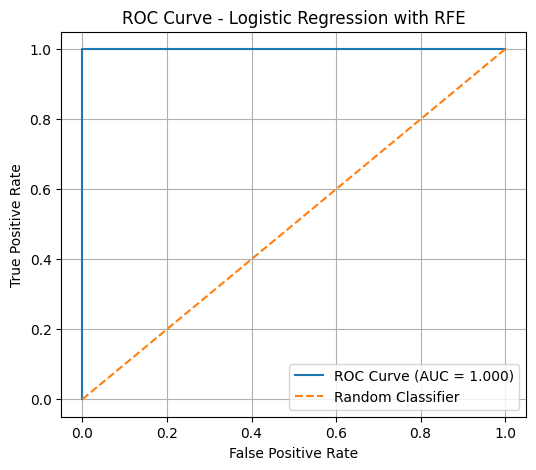

ROC AUC: 1.0


In [51]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = final_model.predict_proba(X_test_best)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_best, y_prob)
auc_score = roc_auc_score(y_test_best, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression with RFE")
plt.legend()
plt.grid(True)
plt.show()

print("ROC AUC:", auc_score)

In [52]:
coefficients = final_model.named_steps["classifier"].coef_[0]

coef_table = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficients
})

display(coef_table)

,Feature,Coefficient
0,3rd_quart1_part1,-0.853990
1,1st_quart4_part1,-0.698944
2,min5_part1,1.408760
3,max5_part1,1.895627
4,1st_quart6_part1,-0.823016


In [53]:
train_predictions = final_model.predict(X_best)

print(
    "Training Accuracy:",
    accuracy_score(y_best, train_predictions)
)

print(
    "Training Confusion Matrix:"
)
print(confusion_matrix(y_best, train_predictions))

Training Accuracy: 1.0
Training Confusion Matrix:
[[60  0]
 [ 0  9]]


2(a)(vi) Complete Separation

**Complete Separation:** The predicted probabilities for the two classes are completely separated in the training data. The maximum predicted probability for non-bending instances (0.4687) is lower than the minimum for bending instances (0.8592).

The unregularized logistic regression model also reported complete separation and failed to converge. Under complete separation, finite maximum likelihood estimates may not exist, making coefficient estimates and associated p-values unreliable. Regularization helps produce finite, more stable estimates.

In [54]:
train_prob = final_model.predict_proba(X_best)[:, 1]

prob_table = pd.DataFrame({
    "Actual": y_best.values,
    "Predicted_Probability": train_prob
})

display(prob_table.groupby("Actual")["Predicted_Probability"].agg(
    ["min", "max", "mean"]
))

,min,max,mean
Actual,,,
0,0.000318,0.468737,0.051191
1,0.859169,0.999951,0.948774


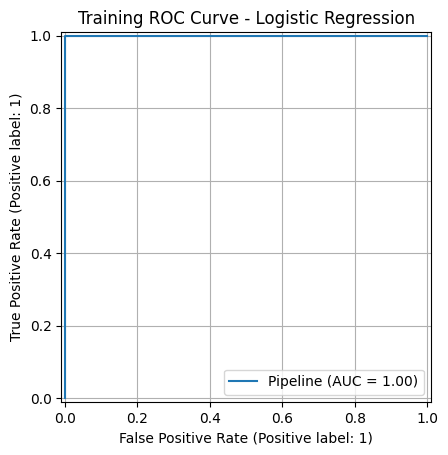

Training AUC: 1.0


In [55]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

RocCurveDisplay.from_estimator(
    final_model,
    X_best,
    y_best
)

plt.title("Training ROC Curve - Logistic Regression")
plt.grid(True)
plt.show()

print(
    "Training AUC:",
    roc_auc_score(
        y_best,
        final_model.predict_proba(X_best)[:, 1]
    )
)

In [72]:
import warnings
from statsmodels.tools.sm_exceptions import (
    PerfectSeparationWarning,
    ConvergenceWarning
)

warnings.filterwarnings("ignore", category=PerfectSeparationWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [73]:
import statsmodels.api as sm

X_selected = final_model.named_steps["scaler"].transform(X_best)
X_selected = final_model.named_steps["rfe"].transform(X_selected)

X_sm = sm.add_constant(X_selected)

try:
    logit_result = sm.Logit(y_best.values, X_sm).fit(disp=False)
    print(logit_result.summary())
except Exception as e:
    print("Model fitting issue:", type(e).__name__)
    print(str(e))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       63
Method:                           MLE   Df Model:                            5
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        06:50:42   Log-Likelihood:            -6.9667e-09
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 2.738e-10
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -49.7216   5.72e+04     -0.001      0.999   -1.12e+05    1.12e+05
x1           -20.1368   9.13e+04     -0.000      1.000   -1.79e+05    1.79e+05
x2            -1.9712   1.47e+05  -1.34e-05      1.0

The logistic regression model exhibits complete separation, as the training observations can be perfectly classified. Consequently, the unregularized maximum likelihood estimates are not finite, and the Statsmodels optimization fails to converge. The resulting coefficient estimates, standard errors, and p-values are therefore unreliable. Regularization can help produce finite and more stable estimates.

## 2(b) Binary Classification Using L1-Penalized Logistic Regression

### 2(b)(i) L1 Regularization and Cross-Validation

In [57]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import make_pipeline

X, y = training_data_by_l[1]

l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        Cs=10,
        cv=cv,
        penalty="l1",
        solver="liblinear",
        max_iter=10000,
        scoring="accuracy",
        class_weight="balanced",
        random_state=42
    )
)

l1_model.fit(X, y)

print("Best C:", l1_model.named_steps["logisticregressioncv"].C_[0])
print("Training Accuracy:", l1_model.score(X, y))

Best C: 10000.0
Training Accuracy: 1.0


In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

l1_results = []

for l in range(1, 21):
    X, y = training_data_by_l[l]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            class_weight="balanced",
            max_iter=10000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        model,
        param_grid={
            "classifier__C": np.logspace(-3, 4, 8)
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X, y)

    l1_results.append({
        "l": l,
        "Best C": search.best_params_["classifier__C"],
        "CV Accuracy": search.best_score_,
        "CV Error": 1 - search.best_score_
    })

    print(f"Finished l={l}")

l1_results_df = pd.DataFrame(l1_results)

display(
    l1_results_df.sort_values(
        ["CV Error", "l"]
    ).head(10)
)

Finished l=1
Finished l=2
Finished l=3
Finished l=4
Finished l=5
Finished l=6
Finished l=7
Finished l=8
Finished l=9
Finished l=10
Finished l=11
Finished l=12
Finished l=13
Finished l=14
Finished l=15
Finished l=16
Finished l=17
Finished l=18
Finished l=19
Finished l=20


,l,Best C,CV Accuracy,CV Error
0,1,10000.0,0.985714,0.014286
19,20,1.0,0.985714,0.014286
9,10,10.0,0.971429,0.028571
10,11,1.0,0.971429,0.028571
11,12,1.0,0.971429,0.028571
16,17,100.0,0.971429,0.028571
17,18,1.0,0.971429,0.028571
18,19,1.0,0.971429,0.028571
7,8,10.0,0.957143,0.042857
1,2,100.0,0.957143,0.042857


In [59]:
best_l = 1
best_C = 10000

X_train_l1, y_train_l1 = training_data_by_l[best_l]

best_l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=best_C,
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    )
)

best_l1_model.fit(X_train_l1, y_train_l1)

X_test_l1 = test_l1.drop(columns=["activity", "dataset"])
y_test_l1 = test_l1["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

l1_predictions = best_l1_model.predict(X_test_l1)

print("Test Accuracy:", accuracy_score(y_test_l1, l1_predictions))
print("Test Error:", 1 - accuracy_score(y_test_l1, l1_predictions))
print("Confusion Matrix:")
print(confusion_matrix(y_test_l1, l1_predictions))

print(
    "Non-zero coefficients:",
    np.count_nonzero(best_l1_model.named_steps["logisticregression"].coef_)
)

Test Accuracy: 1.0
Test Error: 0.0
Confusion Matrix:
[[15  0]
 [ 0  4]]
Non-zero coefficients: 37


### 2(b)(ii) Comparison of L1 Regularization and RFE

L1-penalized logistic regression achieved a cross-validation accuracy of 98.57%, compared with 97.14% for logistic regression with RFE. Both methods achieved 100% accuracy on the test set.

RFE selected only 5 features, whereas the L1 model retained 37 non-zero coefficients. Therefore, RFE produced a more compact model.

L1 regularization is generally easier to implement because feature selection is performed automatically through coefficient shrinkage. In contrast, RFE requires repeated model fitting and selection of the number of features.

Overall, L1 performed slightly better in cross-validation, while RFE provided a simpler model.

## 2(c) Multiclass Classification (The Realistic Case)

### 2(c)(i) L1-Penalized Multiclass Logistic Regression

In [60]:
# Prepare multiclass training data

X_multi, _ = training_data_by_l[1]

y_multi = train_l1["activity"]

print("Training shape:", X_multi.shape)
print("\nActivity counts:")
print(y_multi.value_counts())

Training shape: (69, 42)

Activity counts:
activity
cycling     12
sitting     12
lying       12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


In [61]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="saga",
        C=1.0,
        max_iter=10000,
        random_state=42
    )
)

scores_multi = cross_val_score(
    multi_model,
    X_multi,
    y_multi,
    cv=cv_multi,
    scoring="accuracy"
)

print("CV Accuracy:", scores_multi.mean())
print("CV Error:", 1 - scores_multi.mean())

CV Accuracy: 0.8700980392156863
CV Error: 0.1299019607843137


In [62]:
multi_results = []

for l in range(1, 21):
    X, _ = training_data_by_l[l]

    table = build_feature_table(l)
    mask = table.apply(is_test_instance, axis=1)
    y = table.loc[~mask, "activity"]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=10000,
            random_state=42
        )
    )

    search = GridSearchCV(
        model,
        param_grid={
            "logisticregression__C": [0.01, 0.1, 1, 10, 100]
        },
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X, y)

    multi_results.append({
        "l": l,
        "Best C": search.best_params_["logisticregression__C"],
        "CV Accuracy": search.best_score_,
        "CV Error": 1 - search.best_score_
    })

    print(f"Finished l={l}")

multi_results_df = pd.DataFrame(multi_results)

display(
    multi_results_df.sort_values(
        ["CV Error", "l"]
    ).head(10)
)

Finished l=1
Finished l=2
Finished l=3
Finished l=4
Finished l=5
Finished l=6
Finished l=7
Finished l=8
Finished l=9
Finished l=10
Finished l=11
Finished l=12
Finished l=13
Finished l=14
Finished l=15
Finished l=16
Finished l=17
Finished l=18
Finished l=19
Finished l=20


,l,Best C,CV Accuracy,CV Error
1,2,100,0.883170,0.116830
0,1,1,0.870098,0.129902
5,6,100,0.870098,0.129902
4,5,100,0.869281,0.130719
8,9,10,0.869281,0.130719
3,4,100,0.854575,0.145425
19,20,10,0.854575,0.145425
17,18,10,0.840686,0.159314
10,11,100,0.840686,0.159314
16,17,1,0.840686,0.159314


In [63]:
# Best multiclass L1 Logistic Regression

best_multi_l = 2
best_multi_C = 100

X_multi_train, _ = training_data_by_l[best_multi_l]

table_multi = build_feature_table(best_multi_l)
mask_multi = table_multi.apply(is_test_instance, axis=1)

y_multi_train = table_multi.loc[~mask_multi, "activity"]

X_multi_test = table_multi.loc[
    mask_multi
].drop(columns=["activity", "dataset"])

y_multi_test = table_multi.loc[mask_multi, "activity"]

best_multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="saga",
        C=best_multi_C,
        max_iter=10000,
        random_state=42
    )
)

best_multi_model.fit(X_multi_train, y_multi_train)

multi_pred = best_multi_model.predict(X_multi_test)

print("Test Accuracy:", accuracy_score(y_multi_test, multi_pred))
print("Test Error:", 1 - accuracy_score(y_multi_test, multi_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_multi_test, multi_pred))

Test Accuracy: 0.8421052631578947
Test Error: 0.1578947368421053
Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [1 0 0 0 1 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]


<Figure size 900x700 with 0 Axes>

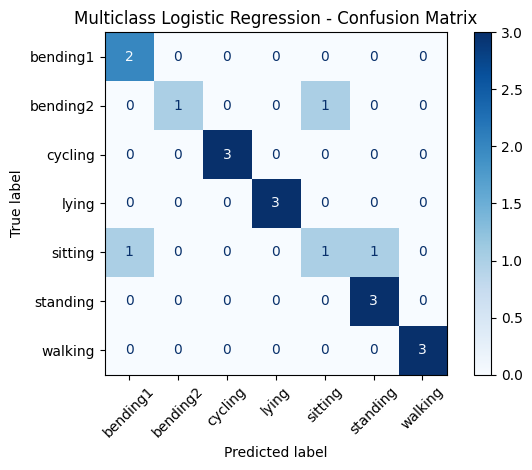

In [64]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_multi_test,
    multi_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Multiclass Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

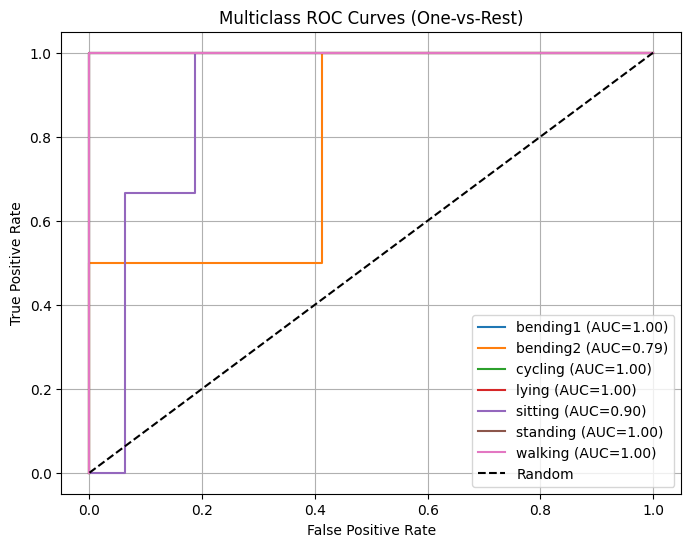

In [65]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

classes = best_multi_model.classes_
y_binary = label_binarize(y_multi_test, classes=classes)
y_prob = best_multi_model.predict_proba(X_multi_test)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_binary[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{activity} (AUC={roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.legend()
plt.grid(True)
plt.show()

### 2(c)(ii) Naive Bayes Classification

#### Gaussian Naive Bayes

In [66]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

X_nb, _ = training_data_by_l[1]

y_nb = train_l1["activity"]

gnb_model = GaussianNB()

gnb_scores = cross_val_score(
    gnb_model,
    X_nb,
    y_nb,
    cv=cv_multi,
    scoring="accuracy"
)

print("Gaussian NB CV Accuracy:", gnb_scores.mean())
print("Gaussian NB CV Error:", 1 - gnb_scores.mean())

Gaussian NB CV Accuracy: 0.8415032679738563
Gaussian NB CV Error: 0.15849673202614367


In [67]:
gnb_results = []

for l in range(1, 21):
    X, _ = training_data_by_l[l]

    scores = cross_val_score(
        GaussianNB(),
        X,
        y_nb,
        cv=cv_multi,
        scoring="accuracy"
    )

    gnb_results.append({
        "l": l,
        "CV Accuracy": scores.mean(),
        "CV Error": 1 - scores.mean()
    })

gnb_results_df = pd.DataFrame(gnb_results)

display(
    gnb_results_df.sort_values(
        ["CV Error", "l"]
    ).head(10)
)

,l,CV Accuracy,CV Error
0,1,0.841503,0.158497
1,2,0.825980,0.174020
2,3,0.697712,0.302288
3,4,0.695261,0.304739
5,6,0.651961,0.348039
7,8,0.638072,0.361928
4,5,0.637255,0.362745
6,7,0.624183,0.375817
9,10,0.622549,0.377451
10,11,0.607843,0.392157


In [68]:
# Train and evaluate the best Gaussian Naive Bayes model

best_gnb_l = 1

X_gnb_train, _ = training_data_by_l[best_gnb_l]

table_gnb = build_feature_table(best_gnb_l)
mask_gnb = table_gnb.apply(is_test_instance, axis=1)

X_gnb_test = table_gnb.loc[mask_gnb].drop(
    columns=["activity", "dataset"]
)
y_gnb_test = table_gnb.loc[mask_gnb, "activity"]

best_gnb_model = GaussianNB()
best_gnb_model.fit(X_gnb_train, y_nb)

gnb_pred = best_gnb_model.predict(X_gnb_test)

print("Test Accuracy:", accuracy_score(y_gnb_test, gnb_pred))
print("Test Error:", 1 - accuracy_score(y_gnb_test, gnb_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_gnb_test, gnb_pred))

Test Accuracy: 0.8947368421052632
Test Error: 0.10526315789473684
Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 2 1 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]


#### Multinomial Naive Bayes

In [69]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline

mnb_model = make_pipeline(
    MinMaxScaler(),
    MultinomialNB()
)

mnb_scores = cross_val_score(
    mnb_model,
    X_nb,
    y_nb,
    cv=cv_multi,
    scoring="accuracy"
)

print("Multinomial NB CV Accuracy:", mnb_scores.mean())
print("Multinomial NB CV Error:", 1 - mnb_scores.mean())

Multinomial NB CV Accuracy: 0.7410130718954249
Multinomial NB CV Error: 0.25898692810457513


In [70]:
mnb_results = []

for l in range(1, 21):
    X, _ = training_data_by_l[l]

    model = make_pipeline(
        MinMaxScaler(),
        MultinomialNB()
    )

    scores = cross_val_score(
        model,
        X,
        y_nb,
        cv=cv_multi,
        scoring="accuracy"
    )

    mnb_results.append({
        "l": l,
        "CV Accuracy": scores.mean(),
        "CV Error": 1 - scores.mean()
    })

mnb_results_df = pd.DataFrame(mnb_results)

display(
    mnb_results_df.sort_values(
        ["CV Error", "l"]
    ).head(10)
)

,l,CV Accuracy,CV Error
4,5,0.782680,0.217320
2,3,0.754902,0.245098
1,2,0.754085,0.245915
6,7,0.754085,0.245915
9,10,0.754085,0.245915
0,1,0.741013,0.258987
3,4,0.739379,0.260621
5,6,0.739379,0.260621
8,9,0.739379,0.260621
11,12,0.739379,0.260621


In [71]:
# Evaluate the best Multinomial Naive Bayes model

best_mnb_l = 5

X_mnb_train, _ = training_data_by_l[best_mnb_l]

table_mnb = build_feature_table(best_mnb_l)
mask_mnb = table_mnb.apply(is_test_instance, axis=1)

X_mnb_test = table_mnb.loc[mask_mnb].drop(
    columns=["activity", "dataset"]
)
y_mnb_test = table_mnb.loc[mask_mnb, "activity"]

best_mnb_model = make_pipeline(
    MinMaxScaler(),
    MultinomialNB()
)

best_mnb_model.fit(X_mnb_train, y_nb)

mnb_pred = best_mnb_model.predict(X_mnb_test)

print("Test Accuracy:", accuracy_score(y_mnb_test, mnb_pred))
print("Test Error:", 1 - accuracy_score(y_mnb_test, mnb_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_mnb_test, mnb_pred))

Test Accuracy: 0.7894736842105263
Test Error: 0.21052631578947367
Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 1 0 2 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]


### 2(c)(iii) Comparison of Multiclass Classification Methods

Three classification methods were evaluated using cross-validation and a held-out test set.

L1-penalized logistic regression achieved the highest cross-validation accuracy (88.32%), followed by Gaussian Naive Bayes (84.15%) and Multinomial Naive Bayes (78.27%).

On the test set, Gaussian Naive Bayes achieved the highest accuracy (89.47%), followed by L1-penalized logistic regression (84.21%) and Multinomial Naive Bayes (78.95%).

Gaussian Naive Bayes performed better than Multinomial Naive Bayes on these continuous time-series features. This is consistent with their modeling assumptions: Gaussian Naive Bayes models continuous feature distributions, while Multinomial Naive Bayes is primarily designed for count-based data.

Overall, Gaussian Naive Bayes achieved the lowest test error, while L1-penalized logistic regression achieved the lowest cross-validation error. Since the test set contains only 19 instances, these differences should be interpreted cautiously.